**Bank Term Deposit Subscription**

- Problem: predict whether a customer will subscribe to a term deposit before their next scheduled marketing call.
- Important definition: a *term deposit* is a type of bank savings account where you deposit money for a fixed period and earn interest in return.
- Dataset: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), `bank-full.csv` (45,211 observations), DOI: `10.24432/C5K306`.

- Personalization: a stratified 80% subsample is selected with TKH Student ID `202300404` as the random seed. The same seed is used for the train/test split in the preprocessing notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

# This standardizes all the plots to have a white background with light gridlines for consistency. 
sns.set_theme(style="whitegrid") 

# Open and read the bank-full.csv data file.
try:
    df = pd.read_csv("../data/bank-full.csv", sep=";")
    print("Dataset loaded successfully.")

except FileNotFoundError:
    print("Dataset file not found.")

except pd.errors.EmptyDataError:
    print("Dataset file is empty.")

except Exception as e:
    print(f"Unexpected error: {e}")


Dataset loaded successfully.


In [2]:
# Dataset inspection:

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Column 13: 'campaign'
- 'campaign' refers to the number of times the customer was contacted during the current campaign.
- x = Contacted x days times so far.

Column 14: 'pdays' 
- 'pdays' refers to how many days ago the customer was last contacted.
- -1 = Never previously contacted.
- x = Contacted x days ago.

Column 15: 'previous'
- 'previous' refers to the number of times a customer was contacted before the current marketing campaign.
- x = The customer was contacted x times before.

Column 16: 'poutcome'
- 'poutcome' stands for 'Previous Outcome' which refers to the result of the bank's previous marketing campaign for that customer.
- success = The previous campaign convinced the customer to subscribe.
- failure = The previous campaign did not convince the customer to subscribe.
- other	= The previous campaign had another outcome that wasn't classified as success or failure.
- unknown = The outcome of the previous campaign is not known or was not recorded. So either, 
    - The customer was never contacted before so there is no previous campaign outcome. 
    - Or the customer was contacted before, but the outcome wasn't recorded or is unavailable.

Column 17: 'y' 
- 'y' is the target column. It represents whether a customer subscribed to a term deposit after the bank's marketing campaign.
- yes = The customer subscribed to a term deposit.
- no = The customer did not subscribe to a term deposit.

In [3]:
STUDENT_ID = 202300404
RANDOM_STATE = STUDENT_ID
# random_state is used for reproducibility, meaning it ensures that operations involving randomness produce the same 
# results when run under the same conditions, by using the same split everytime. 

df_personalized, _ = train_test_split(
    df,
    train_size=0.80,                # Using an 80% subsample of the original dataset (required by the assignment). 
    random_state=RANDOM_STATE,      # Using my student ID for the random seed (required by the assignment).
    stratify=df["y"],               # Stratified the target column to preserve the class distribution (required by the assignment).
)

# Renumber the rows to start from 0 again, and drop the old index column. 
df_personalized = df_personalized.reset_index(drop=True)

# Assert the assignment requirement for >1000 rows. 
assert len(df_personalized) >= 1000

print("Original dataset:", df.shape)
print("Personalized dataset:", df_personalized.shape)
display(df_personalized.head())


Original dataset: (45211, 17)
Personalized dataset: (36168, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,36,admin.,single,secondary,no,0,yes,no,cellular,14,jul,80,2,-1,0,unknown,no
1,30,admin.,single,tertiary,no,1535,no,no,cellular,18,aug,67,4,-1,0,unknown,no
2,31,unemployed,single,secondary,no,8304,no,no,cellular,20,oct,164,1,183,1,failure,no
3,37,technician,married,secondary,no,54,yes,yes,cellular,22,jul,106,2,-1,0,unknown,no
4,38,blue-collar,single,tertiary,no,14058,no,no,telephone,17,jul,293,20,-1,0,unknown,no


In [4]:
# Define the directory for the personalized dataset & save it there.

PERSONALIZED_DATA_PATH = "../data/bank_personalized.csv"
df_personalized.to_csv(PERSONALIZED_DATA_PATH, index=False)
print("Saved:", PERSONALIZED_DATA_PATH)


Saved: ../data/bank_personalized.csv


In [5]:
# 1. Quality check: data types, missing values, unique values, and duplicated rows. 

print("Duplicate rows:", df_personalized.duplicated().sum())

quality_summary = pd.DataFrame({
    " dtype": df_personalized.dtypes.astype(str),
    "missing": df_personalized.isna().sum(),
    "unique": df_personalized.nunique(),
})

display(quality_summary)
display(df_personalized.describe().T)


Duplicate rows: 0


,dtype,missing,unique
age,int64,0,77
job,str,0,12
marital,str,0,3
education,str,0,4
default,str,0,2
balance,int64,0,6594
housing,str,0,2
loan,str,0,2
contact,str,0,3
day,int64,0,31


,count,mean,std,min,25%,50%,75%,max
age,36168.0,40.945615,10.627015,18.0,33.0,39.0,48.0,95.0
balance,36168.0,1354.703052,3017.419829,-6847.0,73.0,451.0,1423.0,102127.0
day,36168.0,15.819564,8.317434,1.0,8.0,16.0,21.0,31.0
duration,36168.0,257.294708,256.711356,0.0,102.0,179.0,318.0,4918.0
campaign,36168.0,2.769658,3.112769,1.0,1.0,2.0,3.0,63.0
pdays,36168.0,40.140704,100.131183,-1.0,-1.0,-1.0,-1.0,871.0
previous,36168.0,0.580237,2.385238,0.0,0.0,0.0,0.0,275.0


Important insights:
1. No missing values or duplicated rows.
2. Balance is heavily right-skewed. Mean = ~1,300, Median = ~450, Maximum = ~102,000, which suggests extreme values & possible outliers.
3. Duration is right-skewed. Mean = ~260s, Median = ~180s, Maximum = ~5,000s, which suggests that some calls are significantly longer than others.
4. Campaign may have outliers. Median = 2 contacts, Maximum = 63, which suggests that most customers recieve few contacts, but there are some that receive many.
5. pdays and previous have special distributions. pdays has a median of -1, previous has a median of 0, which suggests that most customers have no recorded previous campaign contact.
6. Most categorical features will need encoding in order to be able to process them. 
7. Duration may be excluded from the prediction model as this information is only available after the call. 
8. "unknown"` is kept as an explicit category because it could contain information. Also, unsupported values should not be invented.

In [6]:
# 2. Train/test split so we can use only the training portion for decision-guiding EDA.

eda_df, eda_holdout = train_test_split(
    df_personalized,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_personalized["y"],
)

print("EDA training portion:", eda_df.shape)
print("Reserved holdout:", eda_holdout.shape)


EDA training portion: (28934, 17)
Reserved holdout: (7234, 17)


In [7]:
# 3. Analyze each categorical feature (excluding y).

categorical_cols = eda_df.select_dtypes(include=["object", "str", "category"]).columns.tolist()
categorical_cols.remove("y")

# Identify the number of unique values, most common category, and percentage of records belonging to that category, for each categorical column.
# Count the number of "unknown" values in each feature to identify if there is incomplete information in the dataset.

category_overview = []
for col in categorical_cols:
    counts = eda_df[col].value_counts()
    unknown_count = int((eda_df[col] == "unknown").sum())
    category_overview.append({
        "feature": col,
        "categories": eda_df[col].nunique(),
        "most_common": counts.index[0],
        "most_common_%": round(counts.iloc[0] / len(eda_df) * 100, 2),
        "unknown_count": unknown_count,
        "unknown_%": round(unknown_count / len(eda_df) * 100, 2),
    })

display(pd.DataFrame(category_overview).set_index("feature"))


,categories,most_common,most_common_%,unknown_count,unknown_%
feature,,,,,
job,12,blue-collar,21.50,189,0.65
marital,3,married,60.11,0,0.00
education,4,secondary,51.38,1169,4.04
default,2,no,98.19,0,0.00
housing,2,yes,55.59,0,0.00
loan,2,no,84.07,0,0.00
contact,3,cellular,64.63,8392,29.00
month,12,may,30.59,0,0.00
poutcome,4,unknown,81.99,23722,81.99


**Key insights:**
1. There is a high percentage of unknown values in poutcome (~82%), which means most customers have no recorded outcome from a previous campaign.  
2. "education" contains some unknown values (~4%), but since these are recorded as a category rather than missing values, they will be kept as a separate category during one-hot encoding.
3. An important uneven distribution is month: ~30% of accounts were contacted in May, which means that marketing activity was concentrated in certain months.

   - Some features seem to be uninsightful:
4. Almost a third of customers (~30%) have an unknown contact method.
5. "default" is highly imbalanced (98.19% no), so almost all customers have no credit default.
6. "loan" is highly imbalanced (~84% no), so most customers do not have a personal loan.

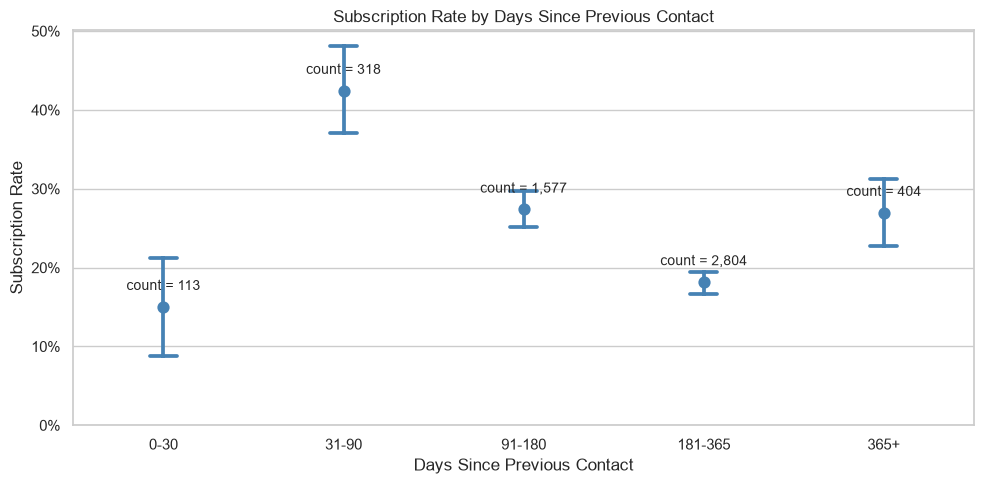

In [8]:
# 4.1: Point plot to investigate whether the time since previous contact is associated with subscription rates (pdays).
# This helps determine whether contact recency could be a useful feature for predicting subscriptions.

plt.figure(figsize=(10, 5))

# Keep only customers who were previously contacted (pdays >= 0).
contacted_df = eda_df[eda_df["pdays"] >= 0].copy()

# Group customers by days since previous contact.
contacted_df["contact_interval"] = pd.cut(
    contacted_df["pdays"],
    bins=[-1, 30, 90, 180, 365, np.inf],
    labels=["0-30", "31-90", "91-180", "181-365", "365+"]
)

# Convert the subscription outcome into binary values (no = 0, yes = 1).
contacted_df["subscribed"] = contacted_df["y"].eq("yes").astype(int)

ax = sns.pointplot(
    data=contacted_df,
    x="contact_interval",
    y="subscribed",
    errorbar=("ci", 95),
    capsize=0.15,
    color="steelblue",
    linestyle="none"
)

# Add customer counts above each plotted point.
for i, (interval, group) in enumerate(
    contacted_df.groupby("contact_interval", observed=True)
):
    rate = group["subscribed"].mean()

    ax.annotate(
        f"count = {len(group):,}",
        xy=(i, rate),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.title("Subscription Rate by Days Since Previous Contact")
plt.xlabel("Days Since Previous Contact")
plt.ylabel("Subscription Rate")
plt.yticks(np.arange(0, 0.6, 0.1), ["0%", "10%", "20%", "30%", "40%", "50%"])
plt.tight_layout()
plt.show()

**Key Findings:**
1. Highest subscription rate: 31–90 days ago with ~42%, based on 318 customers.
2. Lowest subscription rate: 0–30 days ago with ~15%, but this group contains only 113 customers, making the estimate less precise.
3. No consistent trend as the subscription rates do not consistently increase or decrease as the time since previous contact increases. They have a non-linear relationship, meaning that pdays may contain useful information, but its predictive value needs to be evaluated during model training.
4. The 181–365 day group has the largest sample, ~3k customers, and a narrow confidence interval, making its estimated subscription rate (~20%) more precise than the other groups since they are smaller.
5. pdays requires  preprocessing (maybe mnaking it a binary column) since -1 represents no previous contact rather than an actual number of days. If it gets treated a normal numerical value thatr could distort its meaning.

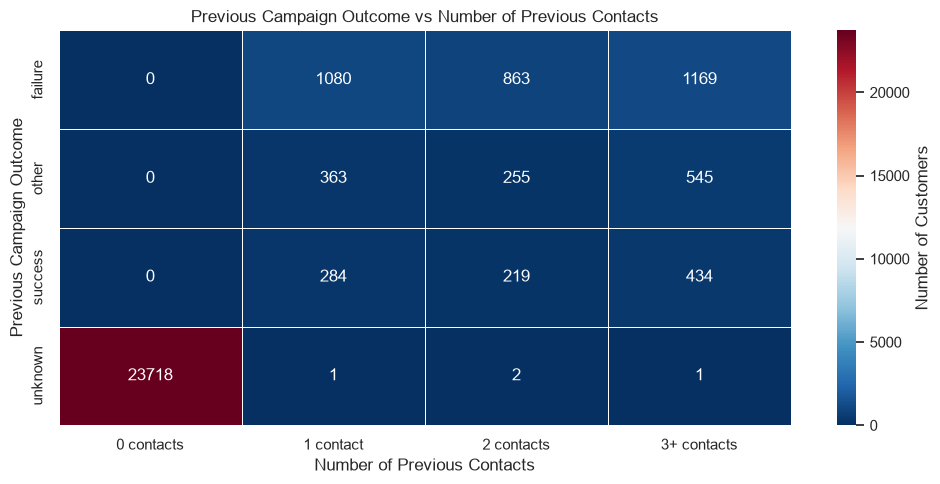

In [9]:
# 4.2: Heatmap to compare previous campaign outcome with previous number of contacts. The goal is to identify the reason behind the 'unkown' outcome.
plt.figure(figsize=(10, 5))


# Group previous contacts into 4 categories using pd.cut (used to group numerical values into categories).
previous_groups = pd.cut(
    eda_df["previous"],
    # np.inf = positive infinity
    bins=[-1, 0, 1, 2, np.inf], 
    labels=["0 contacts", "1 contact", "2 contacts", "3+ contacts"]
)

# Count how many customers belong to each combination.
contact_table = pd.crosstab(
    eda_df["poutcome"],
    previous_groups
)


sns.heatmap(
    contact_table,      
    annot=True,         # Displays the number in each cell.
    fmt="d",            # Numbers as displayed as non-decimal. 
    cmap="RdBu_r",      
    linewidths=0.5,     
    linecolor="white",  
    cbar_kws={"label": "Number of Customers"}
)

plt.title("Previous Campaign Outcome vs Number of Previous Contacts")
plt.xlabel("Number of Previous Contacts")
plt.ylabel("Previous Campaign Outcome")
plt.tight_layout()
plt.show()

**Key Outcomes:**
1. Most customers were not previously contacted. There are ~23.7k customers who were never contacted before and their poutcome is 'unknown' which explains almost all of the unknown outcomes (~80% of the dataset). Only 4 customers with 'unknown' poutcome have a previous campaign history.
2. Most customers were never contacted in previous campaigns. Among those who were, most received only a few contacts, although some extreme values may exist. This indicates a highly right-skewed distribution that may require consideration during preprocessing.

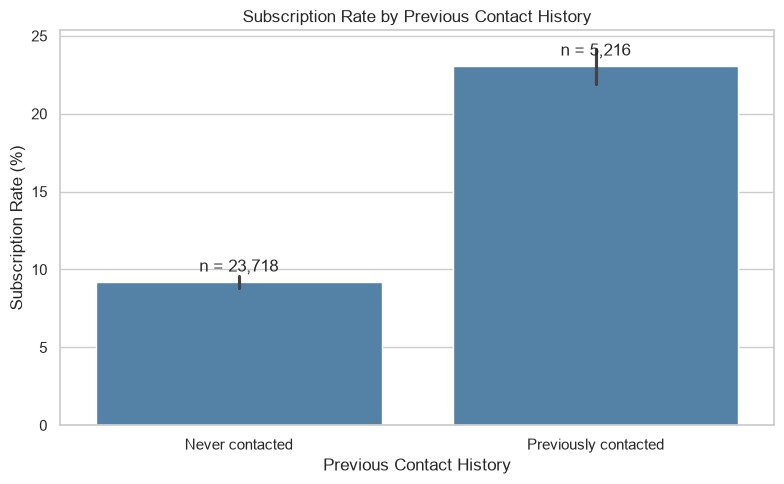

In [10]:
# 4.3: Compare subscription rates between previously contacted and never-contacted customers.
# The point plot excludes customers who were never contacted before. But are customers who have been contacted before more 
# likely to subscribe than customers who have never been contacted?

contact_history = eda_df.copy()

contact_history["previously_contacted"] = np.where(
    contact_history["pdays"] == -1,
    "Never contacted",
    "Previously contacted"
)

contact_history["subscribed"] = contact_history["y"].eq("yes").astype(int) * 100

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=contact_history,
    x="previously_contacted",
    y="subscribed",
    errorbar=("ci", 95),
    color="steelblue"
)

plt.title("Subscription Rate by Previous Contact History")
plt.xlabel("Previous Contact History")
plt.ylabel("Subscription Rate (%)")

# Add the number of customers in each group.
counts = contact_history["previously_contacted"].value_counts()

for bar, category in zip(ax.patches, ["Never contacted", "Previously contacted"]):
    ax.annotate(
        f"n = {counts[category]:,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

**Key Findings**
1. Customers who were previously contacted had a much higher subscription rate (~25%) than those who were never contacted (~10%). 
2. Most customers were never contacted before (~24k), compared to those who were (~5k).
3. Previous contact history may be useful for predicting subscriptions and supports creating a binary previously_contacted feature during preprocessing.

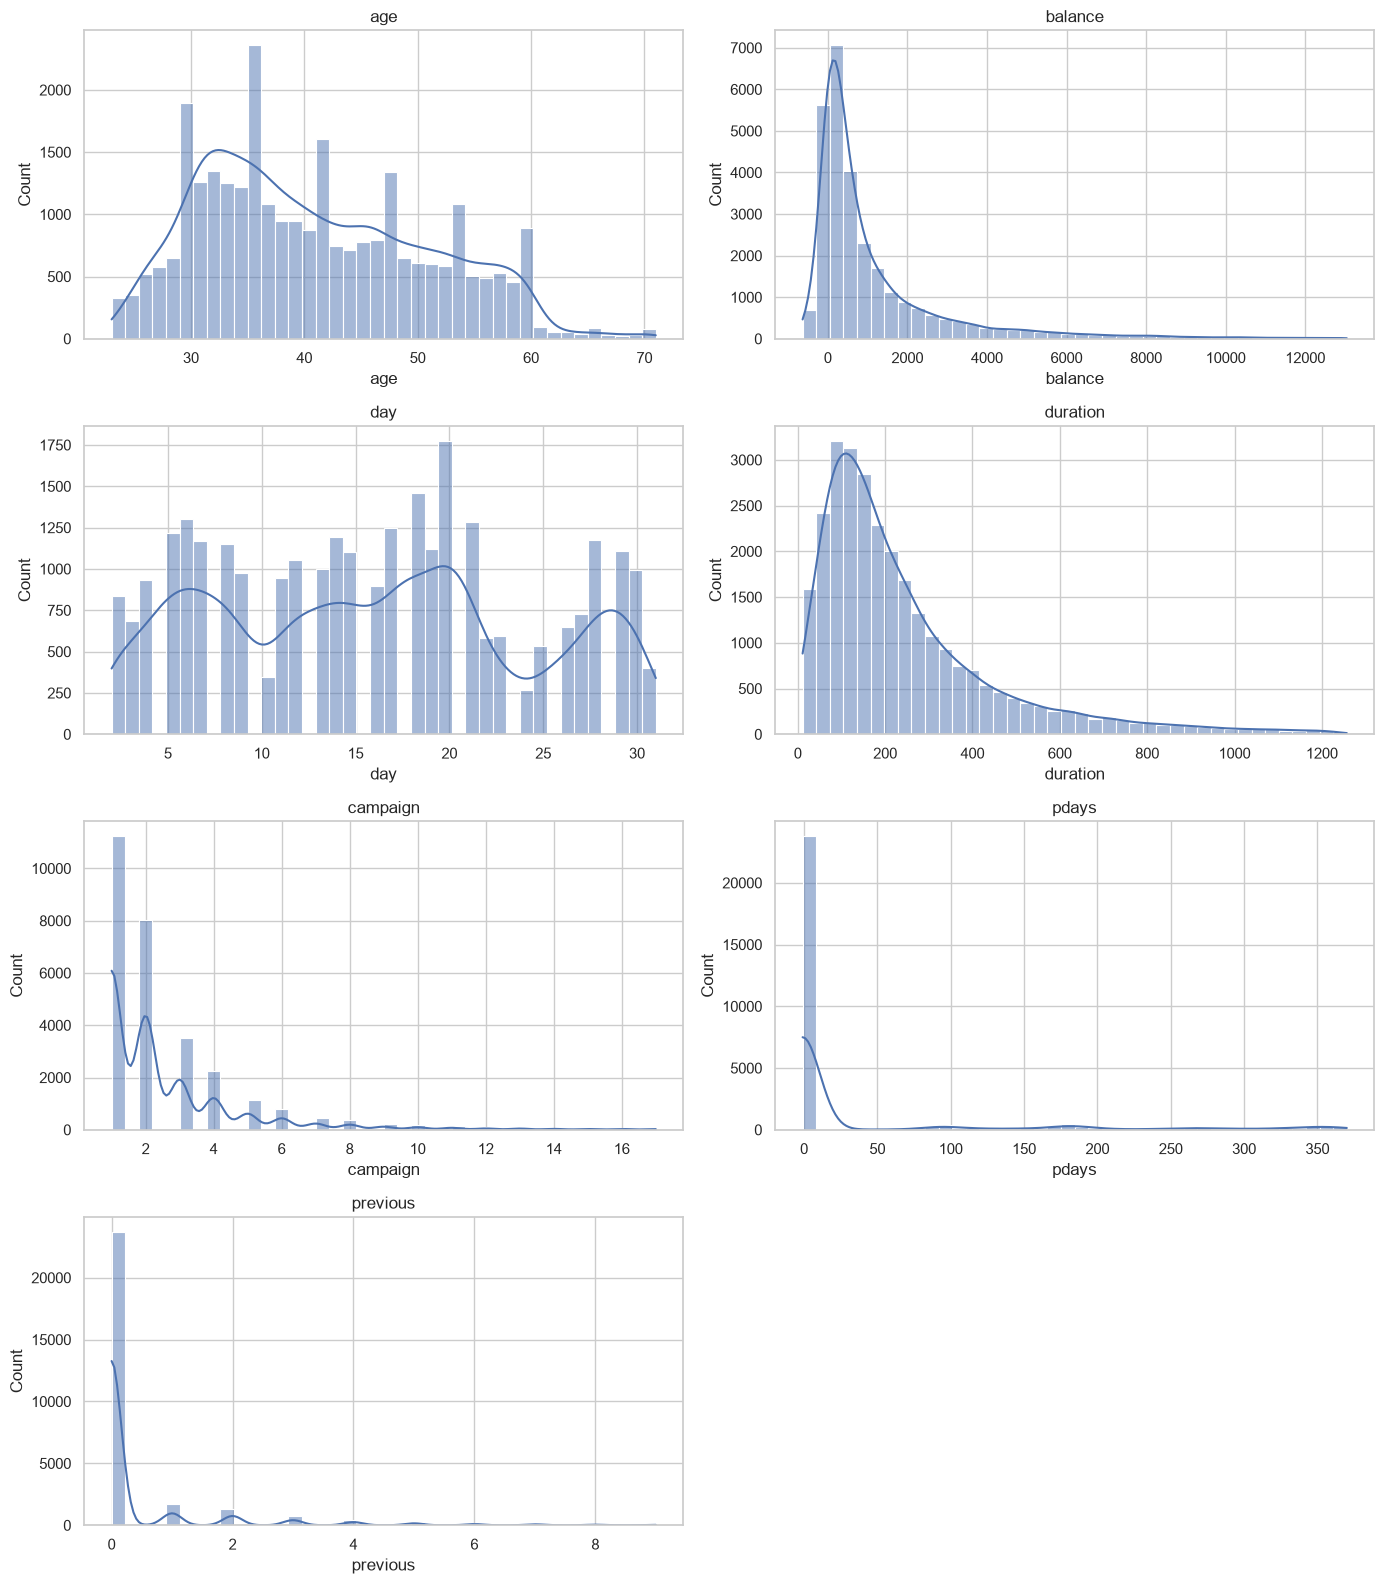

In [11]:
# 5. Histogram investigation for numerical columns (analysing skewness and outliers).

numerical_cols = eda_df.select_dtypes(include=["number"]).columns.tolist()

# Creating a 4x2 grid of 14x16 subplots of every numerical column in the dataset.
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten() # 2D -> 1D makes  looping through the array easier.

for i, col in enumerate(numerical_cols):

    # By focusing on the central 98% of the data, outliers will distort the graph less.
    lower, upper = eda_df[col].quantile([0.01, 0.99])
    central = eda_df.loc[eda_df[col].between(lower, upper), col]

    # Using kde = true to add a smooth curve to estimate the data's distribution.
    sns.histplot(central, bins=40, kde=True, ax=axes[i])
    axes[i].set_title(f"{col}")

# Hide the grid lines in any empty graph slots.
for j in range(len(numerical_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout() # Prevent overlapping
plt.show()


**Key Findings:**
1. balance is very right-skewed. Most customers have relatively low balances, but a small number have much higher balances. These could be potential outliers and could influence scaling in preprocessing.
2. duration is right-skewed: Duration is strongly right-skewed, but it will be excluded from the prediction model because call duration is unknown before the call begins.
3. campaign is very right-skewed: Most customers were contacted only 1–3 times during the current campaign, but some received many.
4. pdays is dominated by -1: The large spike near zero represents customers who were never previously contacted (pdays = -1). This confirms that most customers have no previous campaign history and supports handling -1 separately during preprocessing.
5. previous is highly right-skewed: Most customers have zero previous contacts, while a small number have multiple contacts. This further confirms that previous campaign history is limited for most customers.
6. age: Most customers are concentrated between approximately 30 and 50 years old, with few elderly customers. The distribution is however  less extreme than balance and duration.
7. day: Contacts are not evenly distributed throughout the month, with peaks around certain days, which may reflect the bank's scheduling patterns.

**Overall Conclusion:**
Most numerical features are right-skewed, like balance, duration, campaign, and previous. Numerical preprocessing may require careful scaling and consideration of extreme values rather than assuming approximately normal distributions. However, these histograms display only the central 98% of each feature, meaning some extreme values are not visible.

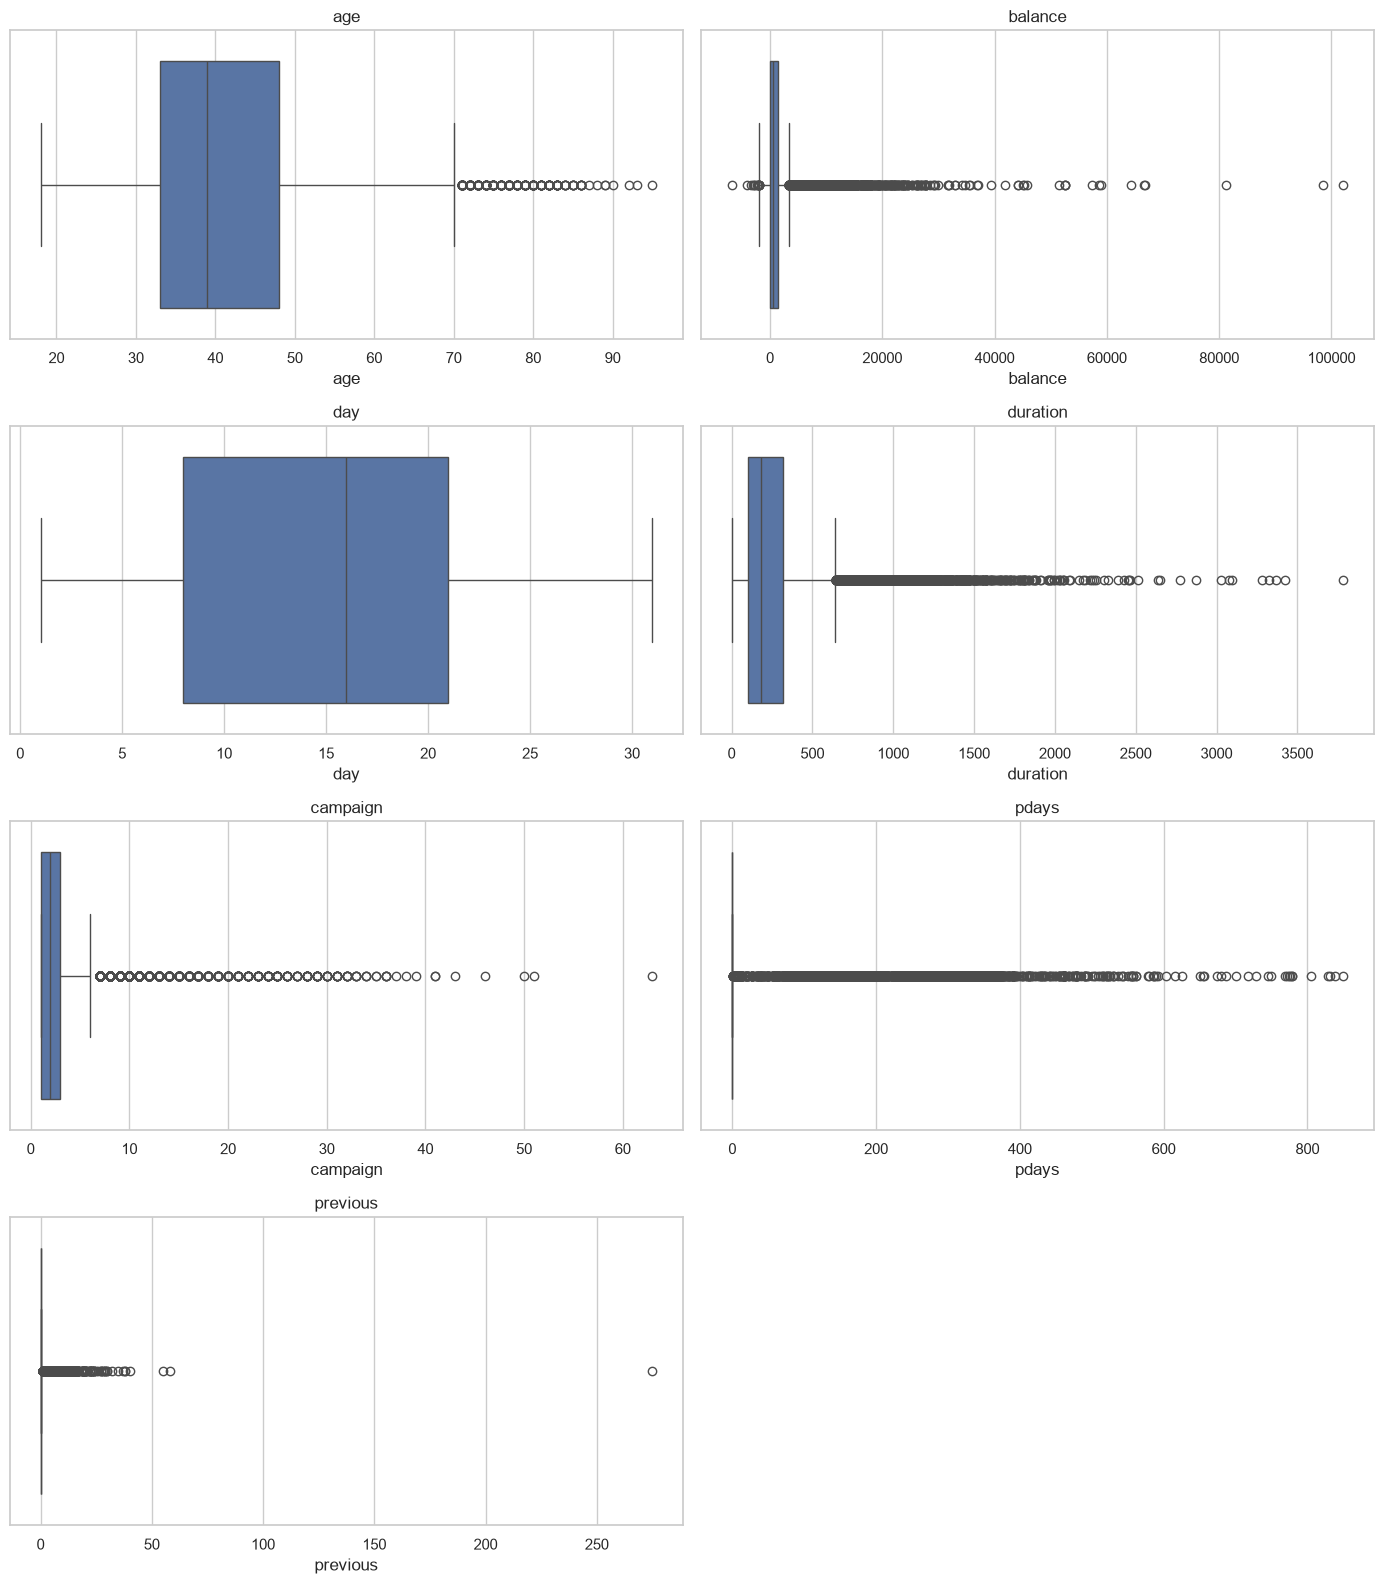

In [12]:
# 6. Boxplot investigation on numerical values: identify potential outliers, and understand their distributions across their full value ranges.

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(x=eda_df[col], ax=axes[i])
    axes[i].set_title(f"{col}")

for j in range(len(numerical_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


**Key Insights:**
1. balance has high-value outliers, some exceed 100,000. These extreme values may affect scaling and certain ML models.
2. duration has high-value outliers, some last over 3,500 seconds. This confirms the right-skewed distribution seen in the histograms.
3. campaign has outliers, some were contacted over 60 times (most are at 1-3 contacts only). That's an unusually high contact count.
4. previous contains an extreme outlier. A customer has 275 previous contacts, which is much higher than the majority. This value should be investigated before deciding on whether or not to transform it.
5. pdays has an unusual distribution because most customers have pdays = -1. But, positive values represent previous contacts and should not automatically be treated as outliers just because -1 has a special meaning. This column might become binary.
6. age has some outliers,some are over 70 (most are between 30 and 45). These are statistically unusual but are not immediately errors.

**Overall Conclusion**
The boxplots confirm that balance, duration, campaign, and previous have right-tailed distributions and potential outliers. These findings suggest considering robust scaling or transformations during preprocessing. However, outliers should not all be removed, since they could represent genuine customer behavior and have useful predictive information.

In [13]:
# 7. Outlier Analysis

outlier_results = []

for col in numerical_cols:
    q1 = eda_df[col].quantile(0.25)
    q3 = eda_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((eda_df[col] < lower) | (eda_df[col] > upper)).sum())
    outlier_results.append({
        "feature": col,
        "skewness": eda_df[col].skew(),
        "IQR": iqr,
        "potential_outliers": count,
        "outlier_%": round(count / len(eda_df) *  100, 2),
    })

display(pd.DataFrame(outlier_results))


,feature,skewness,IQR,potential_outliers,outlier_%
0,age,0.682981,15.0,319,1.10
1,balance,8.999327,1342.0,3038,10.50
2,day,0.098838,13.0,0,0.00
3,duration,3.011233,216.0,2069,7.15
4,campaign,4.804731,2.0,1970,6.81
5,pdays,2.584028,0.0,5216,18.03
6,previous,48.090779,0.0,5216,18.03


**Key Insights:**
1. Previously identified skewness and outliers: previous (48.09), balance (9.00), campaign (4.80), and duration (3.01) are strongly right-skewed, confirming earlier observations. age is moderately skewed (0.68), while day is approximately symmetric (0.10).
2. IQR limitations: pdays and previous have an IQR of 0 because most customers have the same values (-1 and 0). The IQR method flags all other values as potential outliers (18.03%), even though they may be real observations.
3. The IQR method identifies potential outliers in 10.50% of balance values, 7.15% of duration values, and 6.81% of campaign values. This confirms that extreme values are relatively common in these features.

,count,percentage
y,,
no,25549,88.3
yes,3385,11.7


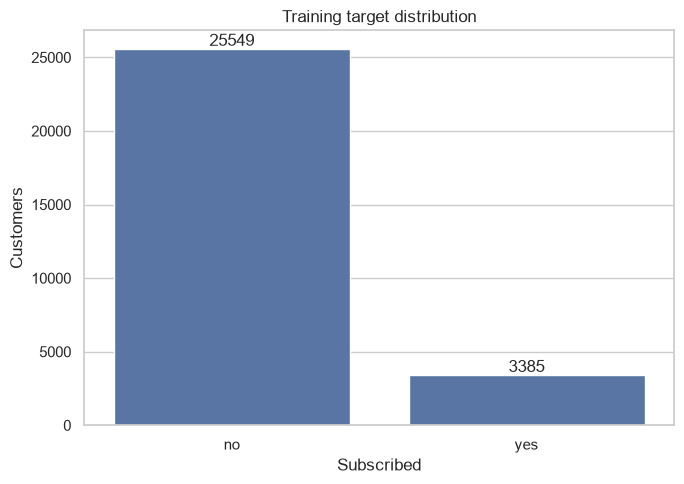

In [14]:
# 8. Calculate count & percentage of each class in the target column to investigate class imbalance.
target_counts = eda_df["y"].value_counts()
target_percentages = eda_df["y"].value_counts(normalize=True).mul(100)
display(pd.DataFrame({"count": target_counts, "percentage": target_percentages.round(2)}))

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=eda_df, x="y", order=["no", "yes"])
ax.set(title="Training target distribution", xlabel="Subscribed", ylabel="Customers")

for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()


**The target variable is highly imbalanced, with ~88% of customers not subscribing and only ~12% subscribing, meaning accuracy alone may be misleading and metrics such as precision, recall, and F1-score should be considered.**

**Findings:**
1. poutcome has a strong association: Customers with previous campaign success have a 66% subscription rate, compared with 9% for unknown outcomes.
2. month shows significant variation: March has the highest subscription rate (~54%), while May has the lowest (~7%).
3. job influences subscription patterns: Students (~29%) and retired customers (~24%) have the highest rates, while blue-collar workers and entrepreneurs have the lowest (~8%).
4. Loans are associated with lower subscription rates: Customers without housing or personal loans are more likely to subscribe.
5. Other demographic factors: Single customers and those with tertiary education show higher subscription rates.
6. Contact method matters: Cellular and telephone contacts have higher subscription rates than unknown contact methods.

**Overall conclusion:**  poutcome and month show the strongest observed differences in subscription rates, while job, loan status, and contact method also appear relevant. These are associations, and category sample sizes should be considered before drawing final conclusions.


y,no,yes
age,39.0,38.0
balance,416.0,724.0
day,16.0,15.0
duration,163.0,428.0
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


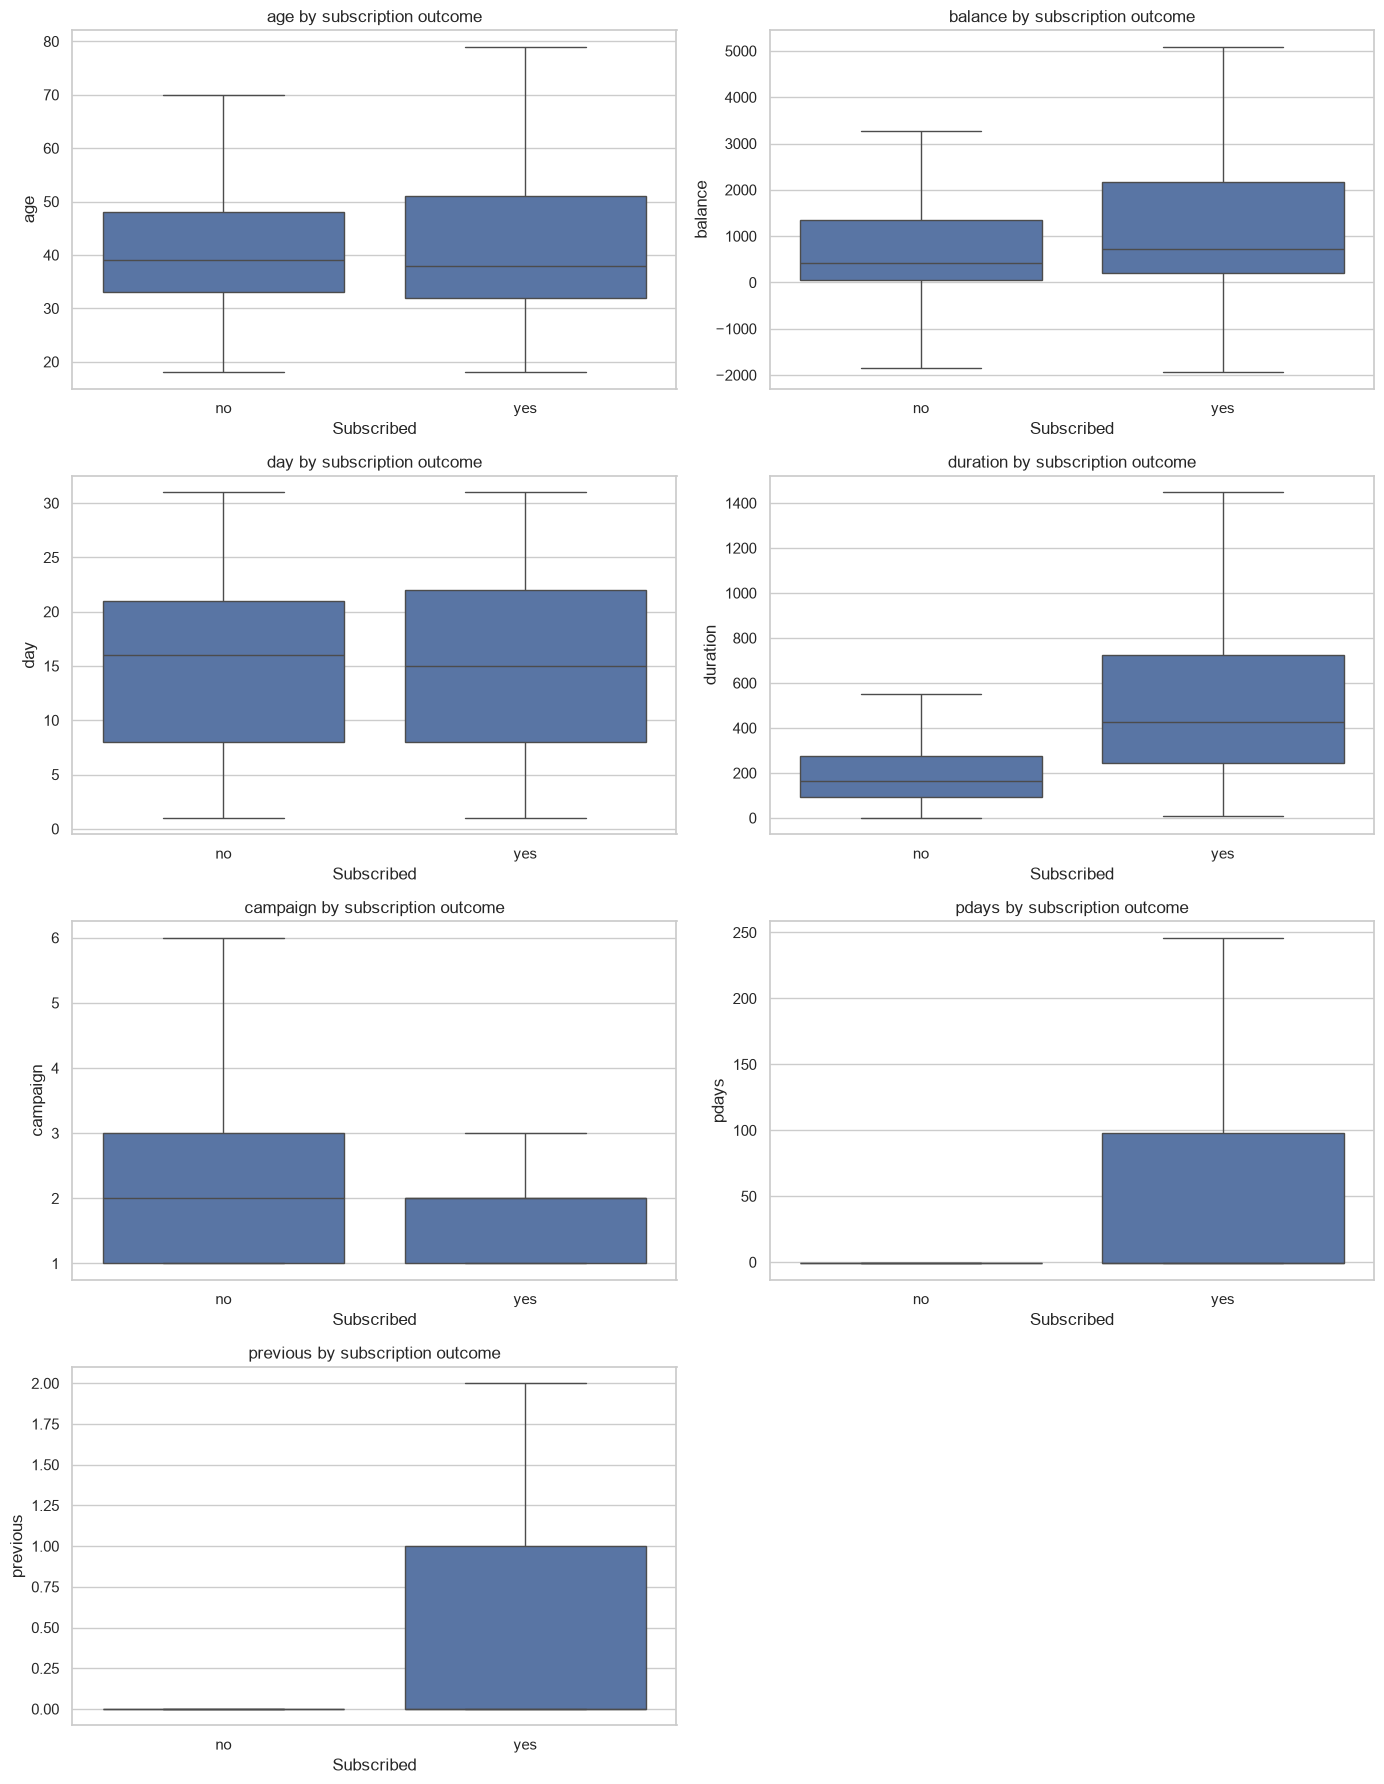

In [15]:
# 10. Compare the median values and distributions of numerical features, between customers who did/didnt subscribe, to identify potential relationships.

median_comparison = eda_df.groupby("y")[numerical_cols].median().T
display(median_comparison)

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(
        data=eda_df,
        x="y",
        y=col,
        order=["no", "yes"],
        showfliers=False,
        ax=axes[i],
    )
    axes[i].set_title(f"{col} by subscription outcome")
    axes[i].set_xlabel("Subscribed")

for j in range(len(numerical_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


**Key Findings:**
1. duration shows the strongest difference but duration should be excluded if predicting subscriptions before making a call, to avoid data leakage.
2. Higher balances are associated with subscriptions.
3. Fewer campaign contacts may be associated with success. Both groups have a median of 2 contacts, but the boxplots show that non-subscribers generally have a wider distribution and more contacts.
4. Previous campaign history: Most customers in both groups were never contacted before. However, customers who subscribed were more likely to have previous contact history, suggesting that past interactions may influence subscription rates.

**Overall Conclusion**
duration and balance show the clearest differences between subscribers and non-subscribers, while previous campaign history and contact frequency may also be relevant. These findings help identify potentially useful predictors, although their actual predictive importance must be evaluated during model training.

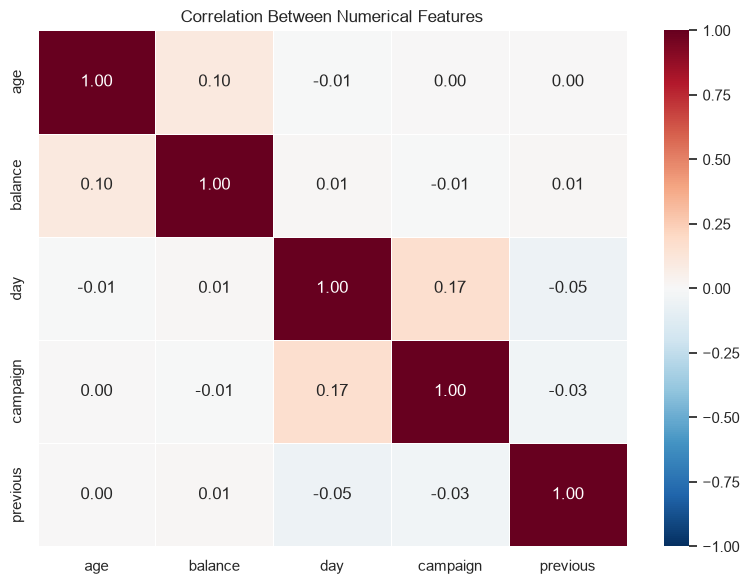

In [16]:
# 11. Investigate correlations between numerical predictors. This helps identify potential relationships and overlapping information.

correlation_cols = [
    "age", "balance", "day", "campaign", "previous"
]

correlation_matrix = eda_df[correlation_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

**Key Finding:** No strong correlations were identified, suggesting that these numerical features are unlikely to cause significant multicollinearity issues based on their correlations.

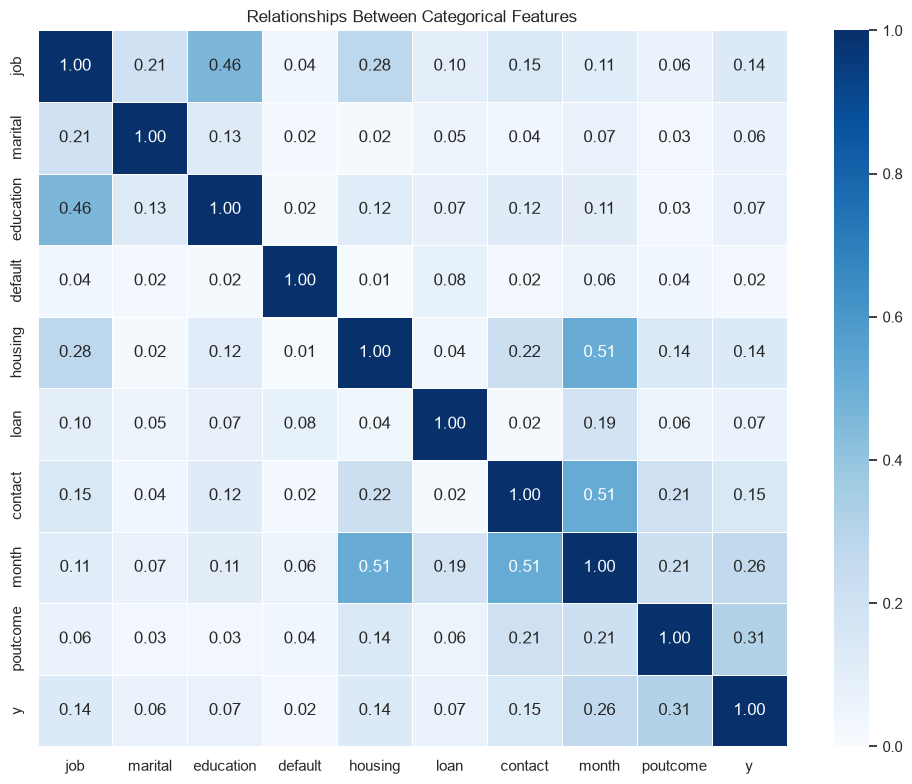

In [17]:
# 12. Investigate relationships between categorical features using a heatmap.

from scipy.stats import chi2_contingency

categorical_cols = [ "job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome", "y"]

# Create an empty correlation matrix.
categorical_corr = pd.DataFrame(
    index=categorical_cols,
    columns=categorical_cols,
    dtype=float
)

# Calculate Cramér's V for each pair of features.
for col1 in categorical_cols:
    for col2 in categorical_cols:

        table = pd.crosstab(eda_df[col1], eda_df[col2])

        chi2 = chi2_contingency(table)[0]
        n = table.to_numpy().sum()

        categorical_corr.loc[col1, col2] = np.sqrt(
            (chi2 / n) / (min(table.shape) - 1)
        )

# Display the heatmap.
plt.figure(figsize=(10, 8))

sns.heatmap(
    categorical_corr,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("Relationships Between Categorical Features")
plt.tight_layout()
plt.show()

**Key Findings:**

1. Subscription outcome: `poutcome` (0.31) and `month` (0.26) have the strongest associations with subscription, making them potentially useful predictors.
2. Feature relationships: `month` has relatively strong associations with `housing` and `contact` (0.51 each), while `job` and `education` are also associated (0.46). These features may contain overlapping information.
3. Weak associations: `default` has almost no association with subscription (0.02), while most other categorical features show weak associations with the target.

Preprocessing decision: keep the categorical features for encoding initially. Features with overlapping information or weak associations should not be automatically removed without evaluating their impact on model performance.

Key EDA Findings for Preprocessing

1. Missing values: No missing values or duplicate rows were found. `"unknown"` values exist in categorical features and should be kept as separate categories.

2. Categorical features: Features like as `job`, `education`, `month`, and `poutcome` need to be encoded. `poutcome` and `month` show strongest categorical associations with subscription outcomes, making them potentially useful predictors.

3. Skewness and outliers: `balance`, `campaign`, and `previous` are very right-skewed and have potential outliers. Scaling or transformations should be considered instead of automatically removing outliers.

4. Previous campaign history: `pdays = -1` represents customers who were never previously contacted. A binary `previously_contacted` feature could be created to preserve this information. The IQR method is unreliable for `pdays` and 'previous' because their IQR is 0. `pdays` should also be preserved for previously contacted customers.

5. Class imbalance: Approximately 88% of customers did not subscribe, compared with 12% who did. Stratified splitting and evaluation metrics such as precision, recall, F1-score, and PR-AUC should be used.

6. Data leakage: `duration` must be excluded because the model aims to predict subscriptions before a marketing call, when call duration is not yet known. Other features, such as campaign, day, month, and contact, must represent information available before that scheduled call.

7. Feature relationships: `month` shows moderate associations with housing and contact (0.51 each), while job and education are also associated (0.46). These features may contain overlapping information but should not be automatically removed.